In [1]:
import pandas as pd

In [2]:

df = pd.read_csv("US_Accidents_March23_sampled_500k.csv")
df.describe()

,Severity,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,500000.000000,500000.000000,500000.000000,279623.000000,279623.000000,500000.000000,489534.000000,370983.000000,488870.000000,491072.000000,488709.000000,463013.000000,357384.000000
mean,2.212748,36.206421,-94.736583,36.273192,-95.776553,0.564317,61.646254,58.229028,64.834921,29.536621,9.091540,7.681347,0.008289
std,0.486661,5.071411,17.405761,5.265333,18.120211,1.774872,19.000133,22.352246,22.826158,1.008666,2.708083,5.431361,0.101865
min,1.000000,24.562117,-124.497420,24.570110,-124.497419,0.000000,-77.800000,-53.200000,1.000000,0.120000,0.000000,0.000000,0.000000
25%,2.000000,33.416823,-117.233047,33.474773,-117.778324,0.000000,49.000000,43.000000,48.000000,29.370000,10.000000,4.600000,0.000000
50%,2.000000,35.832147,-87.794365,36.192669,-88.039013,0.029000,64.000000,62.000000,67.000000,29.860000,10.000000,7.000000,0.000000
75%,2.000000,40.082443,-80.359601,40.181341,-80.252449,0.465000,76.000000,75.000000,84.000000,30.030000,10.000000,10.400000,0.000000
max,4.000000,48.999569,-67.484130,48.998901,-67.484130,193.479996,207.000000,207.000000,100.000000,38.440000,130.000000,822.800000,10.130000


In [3]:
# const value 
FILL_NA_VALUE = "NA"
ZERO = 0
# dropping and filling NA
dfClean = df.drop(["ID", "Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "Wind_Chill(F)", "Airport_Code"], axis=1)
# fill string null will "NA"
dfClean["Description"] = dfClean["Description"].fillna(FILL_NA_VALUE)
dfClean["Street"] = dfClean["Street"].fillna(FILL_NA_VALUE)
dfClean["City"] = dfClean["City"].fillna(FILL_NA_VALUE)
dfClean["Zipcode"] = dfClean["Zipcode"].fillna(FILL_NA_VALUE)
dfClean["Timezone"] = dfClean["Timezone"].fillna(FILL_NA_VALUE)
dfClean["Weather_Timestamp"] = dfClean["Weather_Timestamp"].fillna(FILL_NA_VALUE)
dfClean["Wind_Direction"] = dfClean["Wind_Direction"].fillna(FILL_NA_VALUE)
dfClean["Weather_Condition"] = dfClean["Weather_Condition"].fillna(FILL_NA_VALUE)
dfClean["Sunrise_Sunset"] = dfClean["Sunrise_Sunset"].fillna(FILL_NA_VALUE)
dfClean["Civil_Twilight"] = dfClean["Civil_Twilight"].fillna(FILL_NA_VALUE)
dfClean["Nautical_Twilight"] = dfClean["Nautical_Twilight"].fillna(FILL_NA_VALUE)
dfClean["Astronomical_Twilight"] = dfClean["Astronomical_Twilight"].fillna(FILL_NA_VALUE)

# fill float NA with mean
dfClean["Temperature(F)"] = dfClean["Temperature(F)"].fillna(dfClean["Temperature(F)"].mean())
dfClean["Humidity(%)"] = dfClean["Humidity(%)"].fillna(dfClean["Humidity(%)"].mean())
dfClean["Pressure(in)"] = dfClean["Pressure(in)"].fillna(dfClean["Pressure(in)"].mean())
dfClean["Visibility(mi)"] = dfClean["Visibility(mi)"].fillna(dfClean["Visibility(mi)"].mean())
dfClean["Wind_Speed(mph)"] = dfClean["Wind_Speed(mph)"].fillna(dfClean["Wind_Speed(mph)"].mean())
dfClean["Precipitation(in)"] = dfClean["Precipitation(in)"].fillna(ZERO)

dfClean.info()


<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 39 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Source                 500000 non-null  str    
 1   Severity               500000 non-null  int64  
 2   Start_Time             500000 non-null  str    
 3   End_Time               500000 non-null  str    
 4   Distance(mi)           500000 non-null  float64
 5   Description            500000 non-null  str    
 6   Street                 500000 non-null  str    
 7   City                   500000 non-null  str    
 8   County                 500000 non-null  str    
 9   State                  500000 non-null  str    
 10  Zipcode                500000 non-null  str    
 11  Country                500000 non-null  str    
 12  Timezone               500000 non-null  str    
 13  Weather_Timestamp      500000 non-null  str    
 14  Temperature(F)         500000 non-null  float64

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns


<Axes: title={'center': 'Number of Accident Per State'}, xlabel='State', ylabel='Number of Accident'>

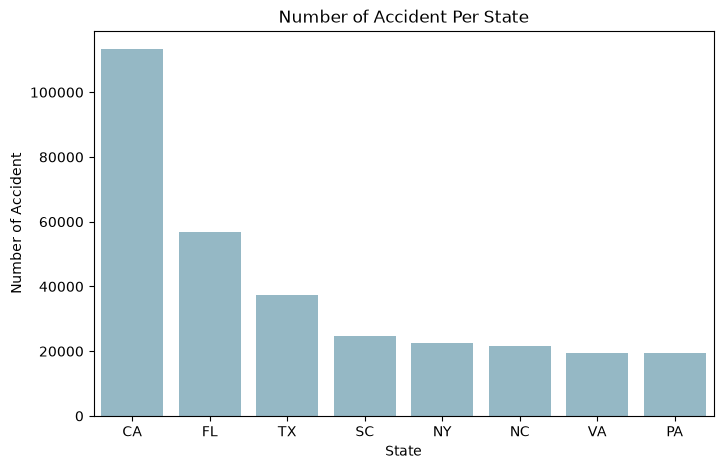

In [29]:
counts = dfClean.groupby("State").count()
numAccidentPerState = counts[counts >= 15000].dropna()


order = numAccidentPerState["Severity"].sort_values(ascending=False).index

plt.figure(figsize=(8,5))
plt.title("Number of Accident Per State")
plt.ylabel("Number of Accident")
sns.barplot(data=numAccidentPerState, x="State", y="Source", order=order, color="#8dbccd")





<Axes: title={'center': 'Number of Accident Per State'}, xlabel='State', ylabel='Number of Accident'>

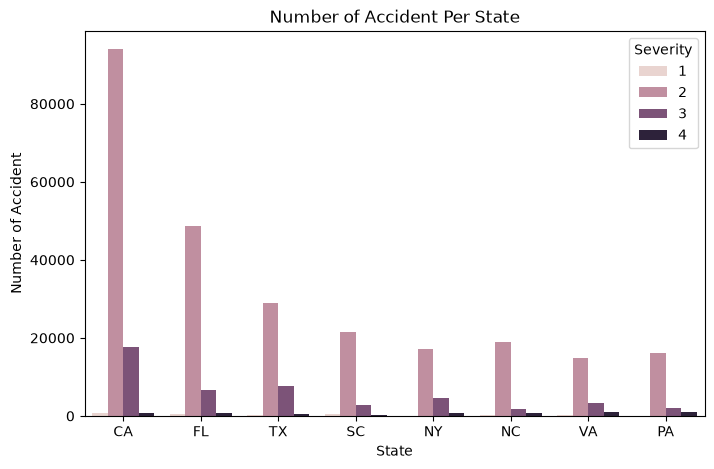

In [31]:
# filter top 8 states

severityPerState = dfClean[dfClean["State"].isin(numAccidentPerState.index)]

plt.figure(figsize=(8,5))
plt.title("Number of Accident Per State")
plt.ylabel("Number of Accident")
sns.countplot(data=severityPerState, x="State", hue="Severity", order=order)

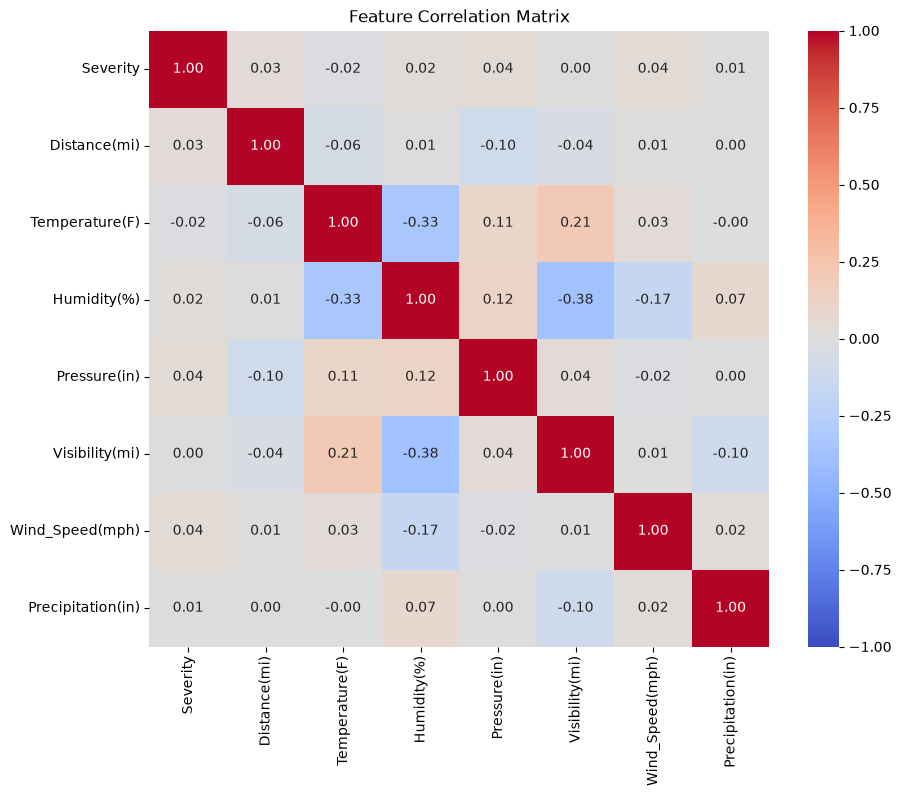

In [37]:
numeric_cols = dfClean.select_dtypes(include=["number"])
plt.figure(figsize=(10,8))
sns.heatmap(numeric_cols.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin = -1, vmax=1)
plt.title("Feature Correlation Matrix")
plt.show()